# Customer churn - JarvisTEC (`churn`)

**Team members:** Anthony Jafeth Arias Robleto (2020007243), Randy Espinoza Downing (2021031263), Kenneth Jhoan Araya Arguedas (2024177221)
**Dataset:** [Telco Customer Churn (GitHub, IBM/telco-customer-churn-on-icp4d)](https://github.com/IBM/telco-customer-churn-on-icp4d), file `data/Telco-Customer-Churn.csv`, a sample dataset published by IBM about the customers of a telecommunications company.

| Section | Points |
|---|---|
| 1. Problem analysis | 0.5 |
| 2. Data understanding | 0.5 |
| 3. Data exploration | 0.5 |
| 4. Model | 2 |
| 5. Evaluation | 1 |
| 6. Conclusion | 0.5 |

## Configuration

In [1]:
import json
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display

warnings.filterwarnings("ignore")

# ------------------------- EDIT THESE VALUES -------------------------
# Must match `name` in backend/models/<package>/adapter.py.
MODEL_NAME = "churn"
# CSV path relative to training/<name>/ (data/ is git-ignored).
DATA_PATH = "../../data/churn/Telco-Customer-Churn.csv"
TARGET_COLUMN = "churn"  # 1 = the customer left, 0 = stayed
TASK_TYPE = "classification"  # "classification" or "regression"
IS_TIME_SERIES = False  # True for bitcoin, avocado...: chronological split
DATE_COLUMN = None  # date column name when IS_TIME_SERIES is True
# An identifier carries no information about the behavior.
EXCLUDED_COLUMNS = ["customer_id"]
SEED = 42
# ---------------------------------------------------------------------

ARTIFACTS = Path("../../artifacts")
ARTIFACTS.mkdir(exist_ok=True)
np.random.seed(SEED)
assert TASK_TYPE in ("classification", "regression")

## 1. Problem analysis

The goal is to estimate whether a **customer of a telecommunications company will leave** (*churn*) from what the company already knows about them: the contract, how long they have been a customer, the services they pay for, how they pay and how much. Keeping a customer is usually cheaper than winning a new one, so a retention team needs a list of the customers most at risk in order to contact them with an offer before they leave.

- **Task type:** binary classification. The target `churn` is `Yes` (the customer left) or `No`; here it is encoded as 1 / 0 so that **churn is the positive class**. The model must also return the **probability** of churn, because a retention team works with a ranked list, not only with a yes/no answer.
- **Success metrics:** only about one customer in four leaves, so **accuracy alone is misleading**: a model that always answers "stays" is right 73 % of the time and identifies no churner. The model is selected by the **F1 of the churn class**, computed with a decision threshold tuned for it, which balances finding the customers who leave (*recall*) against raising false alarms (*precision*). It is also evaluated with **macro F1**, **ROC-AUC** (area under the ROC curve: the quality of the ranking, independent of the threshold), precision, recall and the confusion matrix. It is always compared with a baseline that predicts the most frequent class.
- **Who uses the prediction and what each error costs (assumption):** the retention team uses the ranked list to decide which customers to contact. A **false negative** (a churner the model misses) means the customer leaves without any retention attempt, and the company loses what that customer would have kept paying. A **false positive** (a flagged customer who would have stayed) costs one unnecessary contact and, at worst, a discount given to someone who did not need it. The dataset has no cost or revenue information, so it is an **assumption of this work, not a measured fact**, that a missed churner costs more than an unnecessary retention contact.
- **Why F1 and not recall alone:** under that assumption recall matters more than precision, but without cost figures there is no defensible number for how much more, and maximizing recall alone would simply flag every customer. F1 with a tuned threshold is used as a balance: in section 4 it moves the threshold below 0.5, so more churners are found, while false alarms still count against the model. **Recall and precision are reported separately** everywhere, so the trade-off stays visible and the threshold can be moved once real costs are known.
- **Support:** Verbeke et al. (2012) and Huang et al. (2012) study churn prediction in the telecommunications sector with classification models built on customer attributes of this kind (account, billing and usage data). Verbeke et al. also argue that a churn model should be judged by the value of the retention campaign it enables, not only by statistical measures.

## 2. Data understanding

In [2]:
df = pd.read_csv(DATA_PATH)
print("Rows, columns:", df.shape)
display(df.head())

Rows, columns: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
import re

# snake_case names: the same fields the API receives
# (backend/models/churn/schema.py). "MonthlyCharges" -> "monthly_charges".
df.columns = [
    re.sub(r"(?<=[a-z])(?=[A-Z])", "_", c).lower() for c in df.columns
]

# `total_charges` is a number stored as text; some cells are blank.
blank = df["total_charges"].astype(str).str.strip().eq("")
print("Blank total_charges:", int(blank.sum()))
print("Tenure of those customers:", sorted(df.loc[blank, "tenure"].unique()))
df["total_charges"] = pd.to_numeric(df["total_charges"], errors="coerce")
# They are customers in their first month (tenure 0): nothing billed yet.
df.loc[blank, "total_charges"] = 0.0

# Target as 0/1 so that 1 (churn) is the positive class of every metric.
print("Raw target values:", df[TARGET_COLUMN].value_counts().to_dict())
df[TARGET_COLUMN] = df[TARGET_COLUMN].map({"No": 0, "Yes": 1})

print(
    "Rows identical once customer_id is ignored:",
    int(df.drop(columns="customer_id").duplicated().sum()),
)
display(df.head())

Blank total_charges: 11
Tenure of those customers: [np.int64(0)]
Raw target values: {'No': 5174, 'Yes': 1869}
Rows identical once customer_id is ignored: 22


,customer_id,gender,senior_citizen,partner,dependents,tenure,phone_service,multiple_lines,internet_service,online_security,...,device_protection,tech_support,streaming_tv,streaming_movies,contract,paperless_billing,payment_method,monthly_charges,total_charges,churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


In [4]:
summary = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "% missing": (df.isna().mean() * 100).round(2),
    "unique": df.nunique(),
})
display(summary)
print("Duplicated rows:", df.duplicated().sum())
display(df.describe(include="all").T)

,dtype,missing,% missing,unique
customer_id,str,0,0.0,7043
gender,str,0,0.0,2
senior_citizen,int64,0,0.0,2
partner,str,0,0.0,2
dependents,str,0,0.0,2
tenure,int64,0,0.0,73
phone_service,str,0,0.0,2
multiple_lines,str,0,0.0,3
internet_service,str,0,0.0,3
online_security,str,0,0.0,3


Duplicated rows: 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customer_id,7043,7043,7590-VHVEG,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
senior_citizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
phone_service,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
multiple_lines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
internet_service,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
online_security,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**Data description.** *Telco Customer Churn*, a sample dataset distributed by IBM. Each row is one customer of a telecommunications company: **7043 customers** and 21 columns. Column names are converted to snake_case (`MonthlyCharges` becomes `monthly_charges`) so that they match the API input fields.

| Variable | Meaning | Type / values |
|---|---|---|
| `customer_id` | customer identifier | text, 7043 distinct values (not an input) |
| `gender` | gender | `Female`, `Male` |
| `senior_citizen` | senior citizen flag | integer 0 / 1 |
| `partner`, `dependents` | has a partner / has dependents | `Yes`, `No` |
| `tenure` | time as a customer | months, 0-72 |
| `phone_service` | has phone service | `Yes`, `No` |
| `multiple_lines` | several phone lines | `Yes`, `No`, `No phone service` |
| `internet_service` | internet plan | `DSL`, `Fiber optic`, `No` |
| `online_security`, `online_backup`, `device_protection`, `tech_support`, `streaming_tv`, `streaming_movies` | add-ons of the internet plan | `Yes`, `No`, `No internet service` |
| `contract` | contract term | `Month-to-month`, `One year`, `Two year` |
| `paperless_billing` | paperless billing | `Yes`, `No` |
| `payment_method` | payment method | `Electronic check`, `Mailed check`, `Bank transfer (automatic)`, `Credit card (automatic)` |
| `monthly_charges` | amount billed per month | 18.25-118.75 (the source does not state the currency; US dollars are assumed) |
| `total_charges` | total billed since the customer joined | 0-8684.80, same currency |
| `churn` | the customer left (**target**) | `Yes` / `No`, encoded as 1 / 0 |

**Data quality:**
- **`total_charges` is stored as text**, and **11 cells are blank**. All 11 belong to customers with `tenure` 0 (first month, nothing billed yet), so the blanks are set to 0 instead of being imputed with a typical value. After this step there are no missing values; the `Pipeline` still imputes (median / mode) so that the backend tolerates a missing field.
- **Duplicates:** no row is repeated. When the identifier is ignored, 22 rows are identical to an earlier row. They have different identifiers, so they are treated as different customers with the same profile (few variables, most of them categorical) and are kept. The split cell of section 4 calls `drop_duplicates()` on whole rows, identifier included; since there are 0 exact duplicate rows, **that step removes nothing here** (all 7043 rows go into the split: 5634 train and 1409 test). Its comment ("no row is in both sets") is therefore true only for exact rows: the 22 repeated profiles are not removed, so the same profile can fall on both sides of the split. This is a limitation; it involves 22 of 7043 rows, and how many of them actually ended up split between train and test was not counted.
- **`customer_id` is excluded:** it identifies the row and carries no information about the customer's behavior.
- **Redundant categories:** `No internet service` appears in the six add-on columns for 1526 customers, the same number as `internet_service = No`; `No phone service` in `multiple_lines` repeats `phone_service = No` (682 customers).
- **Imbalance:** 5174 customers stayed and 1869 left (26.5 % churn).
- **Scope:** the data is a snapshot; it has no dates, usage records, complaints or competitor offers.

## 3. Data exploration

churn
0    73.46
1    26.54
Name: % of each class, dtype: float64

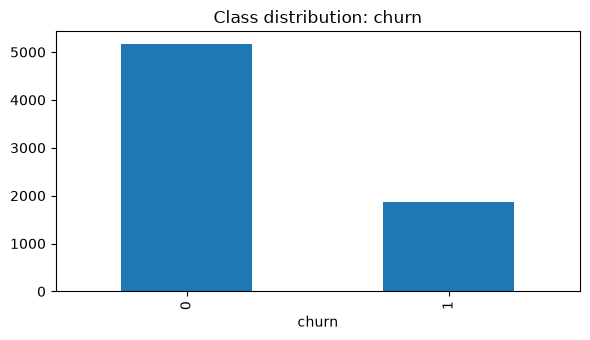

In [5]:
target = TARGET_COLUMN
fig, ax = plt.subplots(figsize=(6, 3.5))
if TASK_TYPE == "classification":
    df[target].value_counts().sort_index().plot(kind="bar", ax=ax)
    ax.set_title(f"Class distribution: {target}")
    shares = (df[target].value_counts(normalize=True) * 100).round(2)
    display(shares.rename("% of each class"))
else:
    df[target].plot(kind="hist", bins=40, ax=ax)
    ax.set_title(f"Distribution of {target}")
plt.tight_layout()
plt.show()

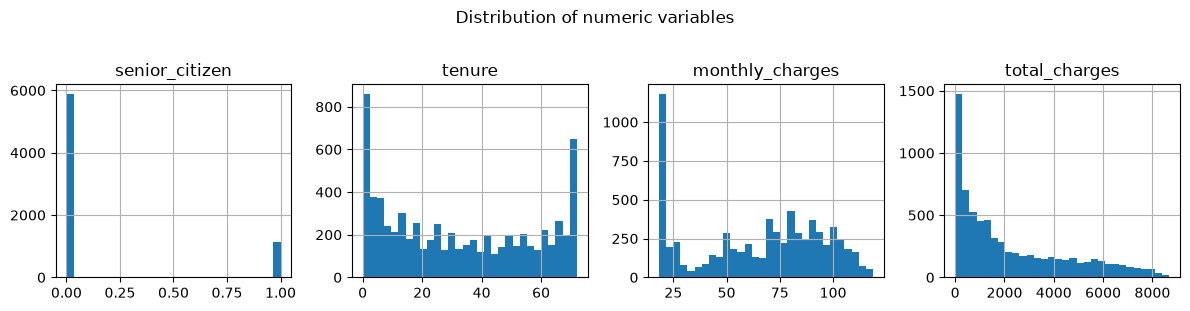

In [6]:
numeric_columns = [
    c for c in df.select_dtypes("number").columns
    if c not in EXCLUDED_COLUMNS + [target]
]
rows = (len(numeric_columns) + 3) // 4
df[numeric_columns].hist(bins=30, figsize=(12, 3 * rows), layout=(-1, 4))
plt.suptitle("Distribution of numeric variables", y=1.02)
plt.tight_layout()
plt.show()

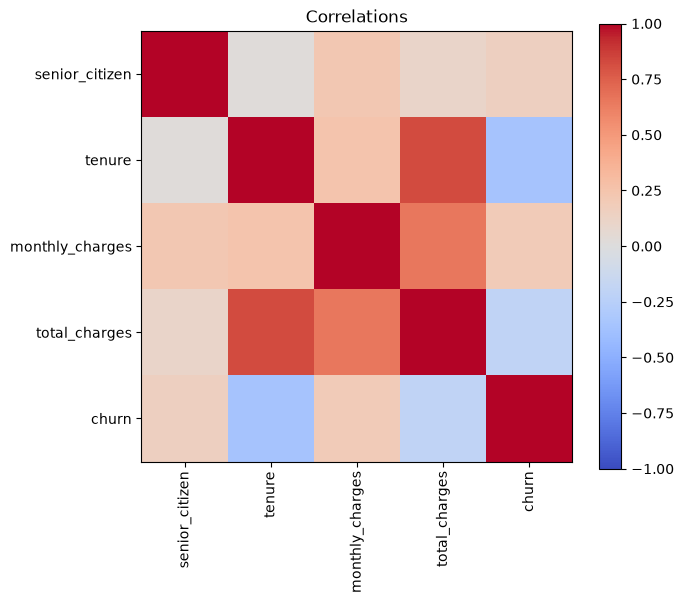

tenure            -0.352229
total_charges     -0.198324
monthly_charges    0.193356
senior_citizen     0.150889
Name: correlation with the target, dtype: float64

In [7]:
if len(numeric_columns) > 1:
    corr = df[numeric_columns + [target]].select_dtypes("number").corr()
    fig, ax = plt.subplots(figsize=(7, 6))
    image = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
    ax.set_xticks(range(len(corr)))
    ax.set_xticklabels(corr.columns, rotation=90)
    ax.set_yticks(range(len(corr)))
    ax.set_yticklabels(corr.columns)
    plt.colorbar(image)
    ax.set_title("Correlations")
    plt.tight_layout()
    plt.show()
    if pd.api.types.is_numeric_dtype(df[target]):
        display(
            corr[target].drop(target)
            .sort_values(key=abs, ascending=False)
            .rename("correlation with the target")
        )

In [8]:
categorical_columns = [
    c for c in df.select_dtypes(exclude="number").columns
    if c not in EXCLUDED_COLUMNS + [target, DATE_COLUMN]
]
for column in categorical_columns[:6]:
    print(f"\n{column}: {df[column].nunique()} categories")
    display(df[column].value_counts().head(10))


gender: 2 categories


gender
Male      3555
Female    3488
Name: count, dtype: int64


partner: 2 categories


partner
No     3641
Yes    3402
Name: count, dtype: int64


dependents: 2 categories


dependents
No     4933
Yes    2110
Name: count, dtype: int64


phone_service: 2 categories


phone_service
Yes    6361
No      682
Name: count, dtype: int64


multiple_lines: 3 categories


multiple_lines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64


internet_service: 3 categories


internet_service
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

,variable,category,customers,churn_rate_%
0,gender,Female,3488,26.9
1,gender,Male,3555,26.2
2,partner,No,3641,33.0
3,partner,Yes,3402,19.7
4,dependents,No,4933,31.3
5,dependents,Yes,2110,15.5
6,phone_service,No,682,24.9
7,phone_service,Yes,6361,26.7
8,multiple_lines,No,3390,25.0
9,multiple_lines,No phone service,682,24.9


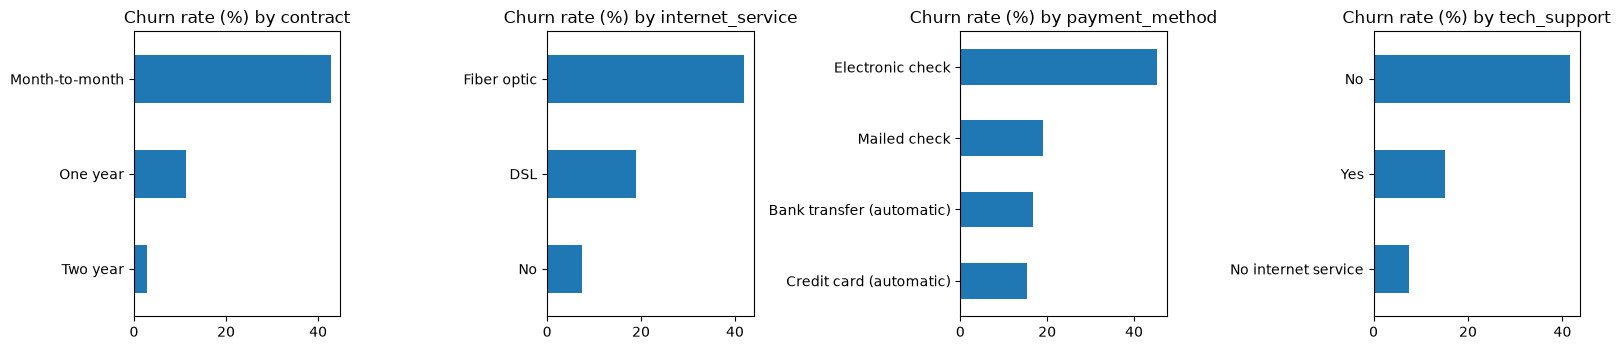

In [9]:
# Churn rate (share of customers who left) for every category.
group_columns = categorical_columns + ["senior_citizen"]
rates = []
for column in group_columns:
    table = df.groupby(column)[target].agg(["size", "mean"])
    for category, row in table.iterrows():
        rates.append({
            "variable": column,
            "category": category,
            "customers": int(row["size"]),
            "churn_rate_%": round(row["mean"] * 100, 1),
        })
rates = pd.DataFrame(rates)
with pd.option_context("display.max_rows", None):
    display(rates)

fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
for ax, column in zip(
    axes, ["contract", "internet_service", "payment_method", "tech_support"]
):
    (df.groupby(column)[target].mean() * 100).sort_values().plot(
        kind="barh", ax=ax
    )
    ax.set_title(f"Churn rate (%) by {column}")
    ax.set_ylabel("")
plt.tight_layout()
plt.show()

,tenure,monthly_charges,total_charges
churn (median values),,,
0,38.0,64.43,1679.52
1,10.0,79.65,703.55


,customers,churn_rate
tenure (months),,
0-6,1481,0.529
7-12,705,0.359
13-24,1024,0.287
25-48,1594,0.204
49-72,2239,0.095


,customers,churn_rate
monthly_charges (USD),,
"(0, 30]",1653,0.098
"(30, 50]",646,0.308
"(50, 70]",1161,0.208
"(70, 90]",1844,0.378
"(90, 120]",1739,0.328


tenure,0-6,7-12,13-24,25-48,49-72
churn rate: contract,,,,,
Month-to-month,0.552,0.420,0.377,0.329,0.260
One year,0.103,0.106,0.081,0.106,0.129
Two year,0.000,0.000,0.000,0.022,0.033


Correlation total_charges vs tenure * monthly_charges: 0.9996


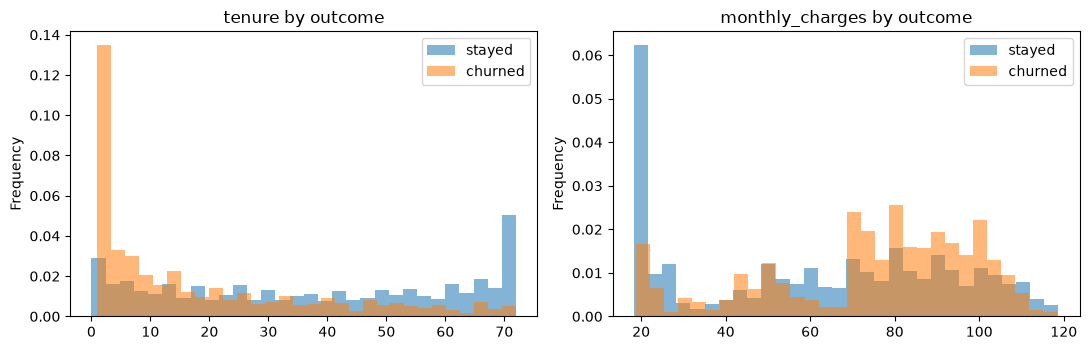

In [10]:
# Numeric variables by outcome, and churn rate along the customer lifetime.
display(
    df.groupby(target)[["tenure", "monthly_charges", "total_charges"]]
    .median().round(2).rename_axis("churn (median values)")
)
tenure_group = pd.cut(
    df["tenure"], [-1, 6, 12, 24, 48, 72],
    labels=["0-6", "7-12", "13-24", "25-48", "49-72"],
)
display(
    df.groupby(tenure_group, observed=True)[target]
    .agg(customers="size", churn_rate="mean").round(3)
    .rename_axis("tenure (months)")
)
charge_group = pd.cut(df["monthly_charges"], [0, 30, 50, 70, 90, 120])
display(
    df.groupby(charge_group, observed=True)[target]
    .agg(customers="size", churn_rate="mean").round(3)
    .rename_axis("monthly_charges (USD)")
)
display(
    pd.crosstab(
        df["contract"], tenure_group, values=df[target], aggfunc="mean"
    ).round(3).rename_axis(index="churn rate: contract", columns="tenure")
)
print(
    "Correlation total_charges vs tenure * monthly_charges:",
    round(df["total_charges"].corr(df["tenure"] * df["monthly_charges"]), 4),
)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, column in zip(axes, ["tenure", "monthly_charges"]):
    for value, label in [(0, "stayed"), (1, "churned")]:
        df.loc[df[target].eq(value), column].plot(
            kind="hist", bins=30, alpha=0.55, density=True, ax=ax,
            label=label,
        )
    ax.set_title(f"{column} by outcome")
    ax.legend()
plt.tight_layout()
plt.show()

**Exploration findings:**

- **Imbalance:** 73.5 % of the customers stayed and **26.5 % left**. For this reason the split is stratified, the model is selected by the F1 of the churn class, and section 4 tries two remedies: class weights and a decision threshold different from 0.5.
- **Numeric distributions (histograms; figures from the summary table of section 2):** `tenure` is spread over the whole range from 0 to 72 months rather than gathered around one value: a quarter of the customers have 9 months or less and a quarter 55 or more (median 29). `monthly_charges` goes from 18.25 to 118.75 with a median of 70.35, and a large group pays very little (1653 customers pay 30 or less per month). `total_charges` is right-skewed (median 1394.55, mean 2279.73, maximum 8684.80), as expected from an amount that accumulates with tenure. `senior_citizen` is a 0 / 1 flag (1142 senior citizens, 16.2 % of the customers), not a quantity. No value is impossible, so no row is treated as an outlier.
- **Category counts:** `gender` (3555 male, 3488 female) and `partner` (3641 without, 3402 with) are balanced, while `dependents` is uneven (4933 without, 2110 with). Almost every customer has phone service (6361 of 7043); the 682 without it are exactly the `No phone service` group of `multiple_lines`, which confirms that this category is redundant. Fiber optic is the most common internet plan (3096), ahead of DSL (2421), and 1526 customers have no internet. The smallest category of any variable has 682 customers (table of churn rates below), so no rare level has to be merged.
- **Contract is the strongest signal:** 42.7 % of the month-to-month customers left, against 11.3 % with a one-year contract and 2.8 % with a two-year contract.
- **New customers leave more:** churn is 52.9 % in the first 6 months and falls steadily to 9.5 % for customers with more than 4 years (49-72 months). `tenure` has the strongest linear correlation with the target (-0.35); the median tenure is 10 months for customers who left and 38 months for those who stayed.
- **Contract and tenure interact:** within month-to-month contracts churn still falls with tenure (from 55.2 % to 26.0 %), while in two-year contracts it is at most 3.3 % in every tenure group. A tree model can capture an interaction like this directly, whereas a purely additive model cannot.
- **Internet plan and add-ons:** fiber optic customers leave much more (41.9 %) than DSL (19.0 %) or customers without internet (7.4 %). Among internet customers, those **without** online security (41.8 % vs. 14.6 %) or tech support (41.6 % vs. 15.2 %) leave more; streaming services make almost no difference (about 30 % vs. 33 %).
- **Price:** customers who left paid more per month (median 79.65 vs. 64.43). The relationship is not monotonic: churn is 9.8 % up to 30 per month, 30.8 % between 30 and 50, 20.8 % between 50 and 70, 37.8 % between 70 and 90 and 32.8 % above 90.
- **Payment and billing:** electronic check stands out (45.3 % churn, against 15-19 % for the other methods), and customers with paperless billing leave about twice as often (33.6 % vs. 16.3 %).
- **Demographics:** senior citizens (41.7 % vs. 23.6 %), customers without a partner (33.0 % vs. 19.7 %) and without dependents (31.3 % vs. 15.5 %) leave more. **Gender makes no difference** (26.9 % vs. 26.2 %), and neither does having phone service (26.7 % vs. 24.9 %).
- **Redundancy:** `total_charges` is almost exactly `tenure * monthly_charges` (correlation 0.9996), so it adds little new information. It is kept because tree models tolerate redundant inputs, but this must be taken into account when reading the feature importances.
- These are **associations, not causes**: each table looks at one variable at a time, and the same customers may combine several of these traits (for example fiber optic, a high monthly charge and a month-to-month contract).

**Preprocessing decisions:** exclude `customer_id`; convert `total_charges` to a number (blank = 0); impute with the median (numeric) or mode (categorical); scale the four numeric variables and one-hot encode the 15 categorical ones, all inside the `Pipeline`. No rows are removed.

## 4. Model

A baseline is compared with several models using cross-validation, and the best one is chosen. All preprocessing lives inside a `Pipeline`, so the backend receives raw data and there is no information leakage.

> **Time series:** not applicable here. The data has no date column (`IS_TIME_SERIES = False`), so a stratified random split and stratified cross-validation are used. A chronological split with `TimeSeriesSplit` would only be required for temporal data.

In [11]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import (
    KFold,
    StratifiedKFold,
    TimeSeriesSplit,
    cross_val_score,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Duplicates removed before splitting, so no row is in both sets.
data = df.drop_duplicates().copy()
if IS_TIME_SERIES and DATE_COLUMN:
    data[DATE_COLUMN] = pd.to_datetime(data[DATE_COLUMN])
    data = data.sort_values(DATE_COLUMN).reset_index(drop=True)

dropped = [TARGET_COLUMN] + EXCLUDED_COLUMNS
dropped += [DATE_COLUMN] if DATE_COLUMN else []
X = data.drop(columns=dropped)
y = data[TARGET_COLUMN]
numeric_features = X.select_dtypes("number").columns.tolist()
categorical_features = X.select_dtypes(exclude="number").columns.tolist()

if IS_TIME_SERIES:
    cut = int(len(X) * 0.8)
    X_train, X_test = X.iloc[:cut], X.iloc[cut:]
    y_train, y_test = y.iloc[:cut], y.iloc[cut:]
    cv = TimeSeriesSplit(n_splits=5)
else:
    stratify = (
        y if TASK_TYPE == "classification" and y.value_counts().min() >= 2
        else None
    )
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=SEED, stratify=stratify
    )
    cv = (
        StratifiedKFold(5, shuffle=True, random_state=SEED)
        if stratify is not None
        else KFold(5, shuffle=True, random_state=SEED)
    )

preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ]), numeric_features),
    ("cat", Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ]), categorical_features),
])
print(f"Train: {X_train.shape}  Test: {X_test.shape}")
print("Numeric:", numeric_features)
print("Categorical:", categorical_features)

Train: (5634, 19)  Test: (1409, 19)
Numeric: ['senior_citizen', 'tenure', 'monthly_charges', 'total_charges']
Categorical: ['gender', 'partner', 'dependents', 'phone_service', 'multiple_lines', 'internet_service', 'online_security', 'online_backup', 'device_protection', 'tech_support', 'streaming_tv', 'streaming_movies', 'contract', 'paperless_billing', 'payment_method']


In [12]:
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import TunedThresholdClassifierCV, cross_validate

THRESHOLD_SUFFIX = " (tuned threshold)"


def tuned_threshold(estimator):
    # Keeps the estimator's probabilities and only moves the decision
    # threshold: the one with the best churn F1 in an internal 5-fold
    # cross-validation of the data it is fitted on.
    return TunedThresholdClassifierCV(estimator, scoring="f1", cv=5)


base_models = {
    "Logistic regression": LogisticRegression(max_iter=1000),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, random_state=SEED, n_jobs=1
    ),
    "Gradient Boosting": GradientBoostingClassifier(random_state=SEED),
}
candidates = {"Baseline": DummyClassifier(strategy="most_frequent")}
candidates.update(base_models)
# Two ways of dealing with the imbalance: class weights...
candidates["Logistic regression (balanced)"] = LogisticRegression(
    max_iter=1000, class_weight="balanced"
)
candidates["Random Forest (balanced)"] = RandomForestClassifier(
    n_estimators=200, random_state=SEED, n_jobs=1, class_weight="balanced"
)
# ...or a decision threshold different from 0.5.
for name, estimator in base_models.items():
    candidates[name + THRESHOLD_SUFFIX] = tuned_threshold(estimator)

# F1 of the churn class (label 1) decides; the rest is reported.
scoring = "f1"
reported = ["f1", "f1_macro", "roc_auc", "precision", "recall", "accuracy"]

score_column = f"{scoring} (mean)"
rows = []
for name, estimator in candidates.items():
    pipeline = Pipeline([("prep", preprocessor), ("model", estimator)])
    scores = cross_validate(
        pipeline, X_train, y_train, cv=cv, scoring=reported, n_jobs=1,
        error_score="raise",
    )
    row = {
        "model": name,
        score_column: scores["test_f1"].mean(),
        "std": scores["test_f1"].std(),
    }
    for metric in reported[1:]:
        row[metric] = scores[f"test_{metric}"].mean()
    rows.append(row)
comparison = (
    pd.DataFrame(rows)
    .sort_values(score_column, ascending=False)
    .reset_index(drop=True)
)
display(comparison.round(4))

,model,f1 (mean),std,f1_macro,roc_auc,precision,recall,accuracy
0,Gradient Boosting (tuned threshold),0.6364,0.0125,0.7355,0.8481,0.5534,0.7492,0.7726
1,Logistic regression (tuned threshold),0.6331,0.0194,0.7301,0.8462,0.5419,0.7639,0.7652
2,Logistic regression (balanced),0.6283,0.0232,0.7191,0.8460,0.5169,0.8013,0.7485
3,Random Forest (tuned threshold),0.6059,0.0235,0.7106,0.8199,0.5190,0.7304,0.7488
4,Random Forest (balanced),0.6020,0.0214,0.7226,0.8223,0.5669,0.6421,0.7749
5,Logistic regression,0.5923,0.0299,0.7308,0.8462,0.6529,0.5431,0.8021
6,Gradient Boosting,0.5878,0.0300,0.7292,0.8481,0.6617,0.5291,0.8032
7,Random Forest,0.5374,0.0278,0.6982,0.8199,0.6222,0.4736,0.7838
8,Baseline,0.0000,0.0000,0.4235,0.5000,0.0000,0.0000,0.7346


**Model choice.** Nine candidates were compared with stratified 5-fold cross-validation (CV) on the training set (5634 customers) and ranked by the F1 of the churn class:
- a **baseline** that always predicts the most frequent class ("stays");
- **logistic regression**, a linear and interpretable model; **Random Forest** (Breiman, 2001) and **Gradient Boosting** (Friedman, 2001), two tree ensembles;
- two remedies for the imbalance (He & Garcia, 2009): **class weights** (`class_weight="balanced"`, for logistic regression and Random Forest), and a **tuned decision threshold** (`TunedThresholdClassifierCV`, for all three models). In the second case the model and its probabilities stay the same, and the threshold that maximizes the churn F1 is chosen with an internal 5-fold cross-validation of the training data, so the comparison stays fair.

| Model | CV F1 (churn) | std | Macro F1 | ROC-AUC | Precision | Recall | Accuracy |
|---|---|---|---|---|---|---|---|
| Gradient Boosting (tuned threshold) | **0.636** | 0.013 | 0.736 | 0.848 | 0.553 | 0.749 | 0.773 |
| Logistic regression (tuned threshold) | 0.633 | 0.019 | 0.730 | 0.846 | 0.542 | 0.764 | 0.765 |
| Logistic regression (balanced) | 0.628 | 0.023 | 0.719 | 0.846 | 0.517 | 0.801 | 0.749 |
| Random Forest (tuned threshold) | 0.606 | 0.024 | 0.711 | 0.820 | 0.519 | 0.730 | 0.749 |
| Random Forest (balanced) | 0.602 | 0.021 | 0.723 | 0.822 | 0.567 | 0.642 | 0.775 |
| Logistic regression | 0.592 | 0.030 | 0.731 | 0.846 | 0.653 | 0.543 | 0.802 |
| Gradient Boosting | 0.588 | 0.030 | 0.729 | 0.848 | 0.662 | 0.529 | 0.803 |
| Random Forest | 0.537 | 0.028 | 0.698 | 0.820 | 0.622 | 0.474 | 0.784 |
| Baseline | 0.000 | 0.000 | 0.424 | 0.500 | 0.000 | 0.000 | 0.735 |

What the table shows:
- **Accuracy is misleading here.** The baseline reaches 0.735 without finding a single churner, and the two models with the highest accuracy (0.80) find only about half of them (recall 0.53-0.54).
- **Dealing with the imbalance matters more than the algorithm.** With the default threshold of 0.5, the models find about half of the churners (recall 0.47-0.54). Tuning the threshold raises the recall of logistic regression and Gradient Boosting to 0.75-0.76, and class weights raise that of logistic regression to 0.80; in all three cases the F1 goes from about 0.59 to about 0.63. Tuning the threshold does not change the ranking quality (ROC-AUC), because the model is the same and only the cut-off moves.
- **Gradient Boosting and logistic regression are tied** (F1 0.636 vs. 0.633, a difference far smaller than the standard deviation across folds, 0.013-0.019; ROC-AUC 0.848 vs. 0.846). Random Forest is slightly behind (F1 0.606, ROC-AUC 0.82).

**Gradient Boosting with a tuned threshold** was chosen because it has the highest cross-validated F1 and ROC-AUC, and tree models can capture the contract-tenure interaction seen in the exploration. The tuned threshold has a further advantage over class weights: it leaves the predicted probabilities untouched, and the backend reports that probability to the user. Logistic regression would be an equally defensible and simpler choice.

**Hyperparameter tuning.** **Only the selected model was tuned.** The other candidates were compared with the fixed hyperparameters shown in the code (in the `tuned threshold` candidates only the decision threshold is fitted), so the table above compares untuned models. `RandomizedSearchCV` evaluated 12 combinations with the same cross-validation, on the training set only (the threshold is re-tuned inside every fit):
- **Searched hyperparameters:** number of trees (100, 200, 300), learning rate (0.03, 0.05, 0.1), tree depth (1, 2, 3), row subsampling (0.8, 1.0) and minimum samples per leaf (1, 20, 50).
- **Best combination:** 300 trees, learning rate 0.03, depth 2, `min_samples_leaf=20` and no row subsampling: many shallow, slow-learning trees with large leaves, a more regularized model than the library default.
- **Result:** the cross-validated F1 went from 0.6364 to 0.6386. It was adopted because the rule is to keep the best cross-validated score, but the gain (0.002) is negligible next to the variation across folds (about 0.017): **tuning barely changed this model**, which suggests that the default configuration was already close to what these variables allow.
- **Decision threshold:** refitted on the whole training set, the tuned threshold is **0.299**: a customer is flagged as "will leave" when the estimated probability is at least 0.299 (about 30 %).

In [13]:
BEST = comparison.loc[~comparison["model"].eq("Baseline"), "model"].iloc[0]
print("Chosen model:", BEST)
final_pipeline = Pipeline([
    ("prep", preprocessor),
    ("model", candidates[BEST]),
])
final_pipeline.fit(X_train, y_train)

Chosen model: Gradient Boosting (tuned threshold)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['gender','senior_citizen','partner',...,'payment_method', 'monthly_charges','total_charges']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passth

In [14]:
# Hyperparameter tuning of the chosen model: cross-validation on TRAIN only.
from sklearn.model_selection import RandomizedSearchCV

SEARCH_SPACES = {
    "Logistic regression": {"C": [0.01, 0.03, 0.1, 0.3, 1.0, 3.0, 10.0]},
    "Random Forest": {
        "n_estimators": [200, 300],
        "max_depth": [6, 10, None],
        "min_samples_leaf": [1, 5, 20],
        "max_features": ["sqrt", 0.5],
    },
    "Gradient Boosting": {
        "n_estimators": [100, 200, 300],
        "learning_rate": [0.03, 0.05, 0.1],
        "max_depth": [1, 2, 3],
        "subsample": [0.8, 1.0],
        "min_samples_leaf": [1, 20, 50],
    },
}
HAS_THRESHOLD = BEST.endswith(THRESHOLD_SUFFIX)
# With a tuned threshold the classifier lives one level deeper.
PREFIX = "model__estimator__" if HAS_THRESHOLD else "model__"
base_name = BEST.removesuffix(THRESHOLD_SUFFIX).removesuffix(" (balanced)")
space = {
    PREFIX + key: values for key, values in SEARCH_SPACES[base_name].items()
}

HYPERPARAMETERS = {}
search = RandomizedSearchCV(
    final_pipeline,
    space,
    n_iter=min(12, int(np.prod([len(v) for v in space.values()]))),
    cv=cv,
    scoring=scoring,
    random_state=SEED,
    n_jobs=1,
    error_score="raise",
)
search.fit(X_train, y_train)
untuned = comparison.loc[comparison["model"].eq(BEST), score_column].iloc[0]
print(
    f"{scoring} CV untuned: {untuned:.4f} | tuned: {search.best_score_:.4f}"
)
results = pd.DataFrame(search.cv_results_).sort_values("rank_test_score")
display(
    results[["params", "mean_test_score", "std_test_score"]].head(5).round(4)
)
if search.best_score_ > untuned:
    final_pipeline = search.best_estimator_
    HYPERPARAMETERS = {
        key.removeprefix(PREFIX): value
        for key, value in search.best_params_.items()
    }
THRESHOLD = 0.5
if HAS_THRESHOLD:
    THRESHOLD = float(final_pipeline.named_steps["model"].best_threshold_)
    HYPERPARAMETERS["decision_threshold"] = round(THRESHOLD, 4)
print("Hyperparameters used:", HYPERPARAMETERS or "defaults")

f1 CV untuned: 0.6364 | tuned: 0.6386


,params,mean_test_score,std_test_score
5,"{'model__estimator__subsample': 1.0, 'model__e...",0.6386,0.0171
9,"{'model__estimator__subsample': 0.8, 'model__e...",0.6374,0.0177
1,"{'model__estimator__subsample': 1.0, 'model__e...",0.6373,0.0194
7,"{'model__estimator__subsample': 1.0, 'model__e...",0.6353,0.0201
2,"{'model__estimator__subsample': 1.0, 'model__e...",0.6335,0.0140


Hyperparameters used: {'subsample': 1.0, 'n_estimators': 300, 'min_samples_leaf': 20, 'max_depth': 2, 'learning_rate': 0.03, 'decision_threshold': 0.299}


## 5. Evaluation

The chosen model is evaluated on the held-out test set, which was not used for training, model selection or tuning. Any other model or rule scored on the test set below is shown for reference only and did not influence a choice.

              precision    recall  f1-score   support

           0       0.90      0.75      0.82      1035
           1       0.53      0.77      0.63       374

    accuracy                           0.76      1409
   macro avg       0.71      0.76      0.72      1409
weighted avg       0.80      0.76      0.77      1409



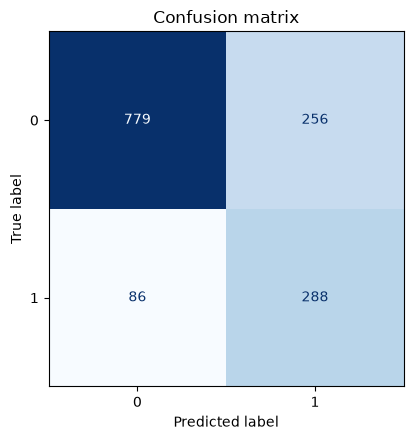

accuracy           0.7573
f1_macro           0.7237
precision_macro    0.7150
recall_macro       0.7614
Name: test metrics, dtype: float64

Baseline f1_macro on test: 0.4235


In [15]:
from sklearn import metrics

predictions = final_pipeline.predict(X_test)

if TASK_TYPE == "classification":
    test_metrics = {
        "accuracy": metrics.accuracy_score(y_test, predictions),
        "f1_macro": metrics.f1_score(y_test, predictions, average="macro"),
        "precision_macro": metrics.precision_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "recall_macro": metrics.recall_score(
            y_test, predictions, average="macro", zero_division=0
        ),
    }
    print(metrics.classification_report(
        y_test, predictions, zero_division=0
    ))
    fig, ax = plt.subplots(figsize=(5, 4.5))
    metrics.ConfusionMatrixDisplay.from_predictions(
        y_test, predictions, ax=ax, cmap="Blues", colorbar=False
    )
    ax.set_title("Confusion matrix")
    plt.tight_layout()
    plt.show()
else:
    test_metrics = {
        "rmse": metrics.mean_squared_error(y_test, predictions) ** 0.5,
        "mae": metrics.mean_absolute_error(y_test, predictions),
        "r2": metrics.r2_score(y_test, predictions),
    }
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].scatter(y_test, predictions, alpha=0.4)
    limits = [
        min(y_test.min(), predictions.min()),
        max(y_test.max(), predictions.max()),
    ]
    ax[0].plot(limits, limits, "r--")
    ax[0].set_xlabel("Actual")
    ax[0].set_ylabel("Predicted")
    ax[0].set_title("Actual vs. predicted")
    ax[1].hist(y_test - predictions, bins=40)
    ax[1].set_title("Residual distribution")
    plt.tight_layout()
    plt.show()

test_metrics = {k: round(float(v), 4) for k, v in test_metrics.items()}
display(pd.Series(test_metrics, name="test metrics"))

# Baseline on the same test set, to check the model really adds value.
baseline = Pipeline([
    ("prep", preprocessor),
    ("model", candidates["Baseline"]),
]).fit(X_train, y_train)
baseline_predictions = baseline.predict(X_test)
if TASK_TYPE == "classification":
    baseline_score = metrics.f1_score(
        y_test, baseline_predictions, average="macro"
    )
    print("Baseline f1_macro on test:", round(baseline_score, 4))
else:
    baseline_score = (
        metrics.mean_squared_error(y_test, baseline_predictions) ** 0.5
    )
    print("Baseline RMSE on test:", round(baseline_score, 4))

accuracy             0.7573
f1_macro             0.7237
precision_macro      0.7150
recall_macro         0.7614
f1_churn             0.6275
precision_churn      0.5294
recall_churn         0.7701
roc_auc              0.8456
average_precision    0.6615
brier_score          0.1356
Name: test metrics, dtype: float64

TN=779  FP=256  FN=86  TP=288  (threshold 0.299)
Churn rate in test: 0.2654
Baseline accuracy on test: 0.7346
Baseline f1_churn on test: 0.0


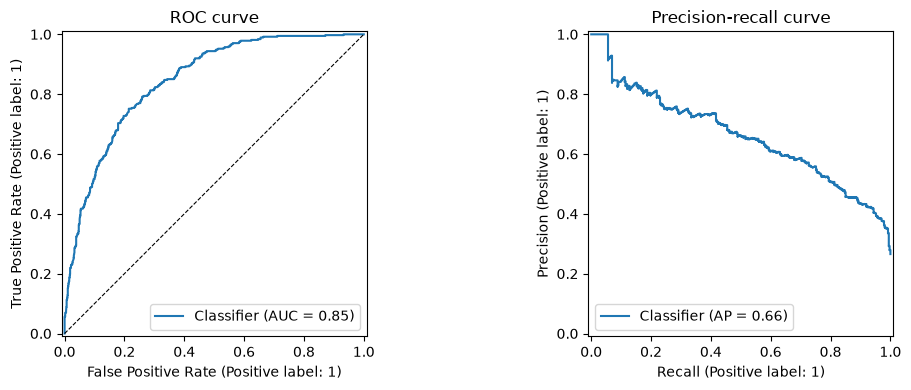

,threshold,flagged_%,precision,recall,f1,accuracy
0,0.2,46.3,0.481,0.840,0.611,0.717
1,0.3,38.3,0.531,0.767,0.628,0.759
2,0.4,29.7,0.591,0.660,0.624,0.789
3,0.5,20.5,0.657,0.508,0.573,0.799
4,0.6,13.3,0.729,0.366,0.488,0.796
5,0.7,6.9,0.804,0.209,0.331,0.776


In [16]:
# Metrics of the churn class (the one that matters) and ranking quality.
POSITIVE = list(final_pipeline.classes_).index(1)
probabilities = final_pipeline.predict_proba(X_test)[:, POSITIVE]
test_metrics.update({
    "f1_churn": metrics.f1_score(y_test, predictions),
    "precision_churn": metrics.precision_score(y_test, predictions),
    "recall_churn": metrics.recall_score(y_test, predictions),
    "roc_auc": metrics.roc_auc_score(y_test, probabilities),
    "average_precision": metrics.average_precision_score(
        y_test, probabilities
    ),
    "brier_score": metrics.brier_score_loss(y_test, probabilities),
})
test_metrics = {k: round(float(v), 4) for k, v in test_metrics.items()}
display(pd.Series(test_metrics, name="test metrics"))

tn, fp, fn, tp = metrics.confusion_matrix(y_test, predictions).ravel()
print(f"TN={tn}  FP={fp}  FN={fn}  TP={tp}  (threshold {THRESHOLD:.3f})")
print("Churn rate in test:", round(float(y_test.mean()), 4))
print("Baseline accuracy on test:", round(
    metrics.accuracy_score(y_test, baseline_predictions), 4
))
print("Baseline f1_churn on test:", round(
    metrics.f1_score(y_test, baseline_predictions, zero_division=0), 4
))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
metrics.RocCurveDisplay.from_predictions(y_test, probabilities, ax=axes[0])
axes[0].plot([0, 1], [0, 1], "k--", linewidth=0.8)
axes[0].set_title("ROC curve")
metrics.PrecisionRecallDisplay.from_predictions(
    y_test, probabilities, ax=axes[1]
)
axes[1].set_title("Precision-recall curve")
plt.tight_layout()
plt.show()

# Same model at other thresholds (reference only, nothing is re-chosen).
rows = []
for threshold in [0.2, 0.3, 0.4, 0.5, 0.6, 0.7]:
    flagged = (probabilities >= threshold).astype(int)
    rows.append({
        "threshold": threshold,
        "flagged_%": round(flagged.mean() * 100, 1),
        "precision": metrics.precision_score(y_test, flagged),
        "recall": metrics.recall_score(y_test, flagged),
        "f1": metrics.f1_score(y_test, flagged),
        "accuracy": metrics.accuracy_score(y_test, flagged),
    })
display(pd.DataFrame(rows).round(3))

cat__contract_Month-to-month            0.3604
num__tenure                             0.1719
cat__internet_service_Fiber optic       0.1258
cat__online_security_No                 0.0820
cat__tech_support_No                    0.0567
cat__payment_method_Electronic check    0.0567
num__monthly_charges                    0.0421
num__total_charges                      0.0411
cat__contract_Two year                  0.0109
cat__multiple_lines_No                  0.0102
cat__online_backup_No                   0.0091
cat__paperless_billing_No               0.0085
Name: Feature importance, dtype: float64

tenure               0.0577
contract             0.0512
internet_service     0.0116
online_security      0.0050
tech_support         0.0043
monthly_charges      0.0038
total_charges        0.0032
payment_method       0.0029
paperless_billing    0.0025
multiple_lines       0.0025
senior_citizen       0.0010
online_backup        0.0003
streaming_movies     0.0003
dependents           0.0002
streaming_tv         0.0002
phone_service        0.0002
device_protection    0.0000
partner              0.0000
gender               0.0000
Name: ROC-AUC drop when shuffled, dtype: float64

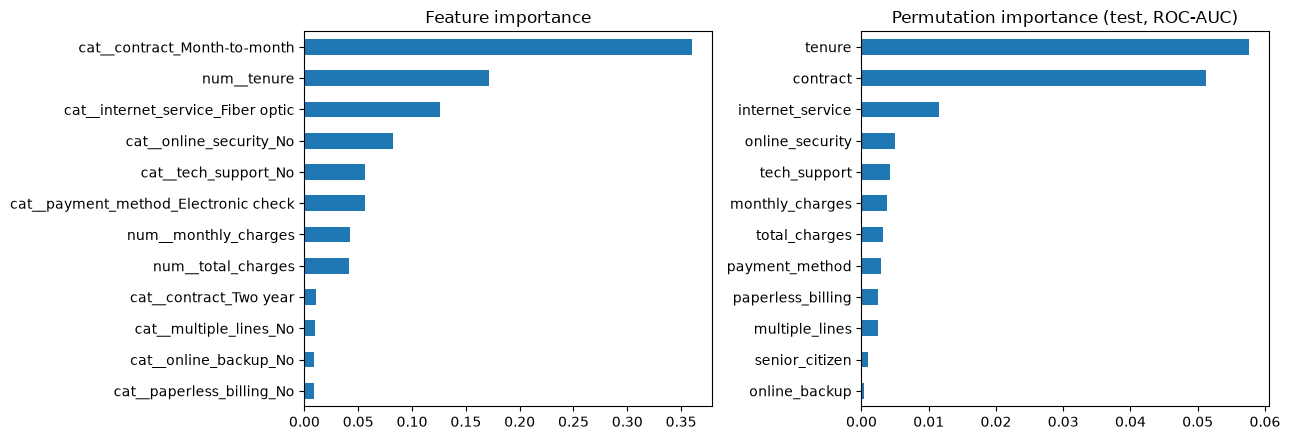

In [17]:
# Feature importance: the model's own (per encoded column) and permutation
# importance on the test set (per raw input, drop in ROC-AUC when shuffled).
from sklearn.inspection import permutation_importance

estimator = final_pipeline.named_steps["model"]
# A tuned-threshold model wraps the fitted classifier.
estimator = getattr(estimator, "estimator_", estimator)
feature_names = final_pipeline.named_steps["prep"].get_feature_names_out()
if hasattr(estimator, "feature_importances_"):
    weights, title = estimator.feature_importances_, "Feature importance"
else:
    weights, title = estimator.coef_[0], "Coefficients (scaled inputs)"
importance = pd.Series(weights, index=feature_names).sort_values(key=abs)
display(importance.tail(12).iloc[::-1].round(4).rename(title))

permutation = permutation_importance(
    final_pipeline, X_test, y_test, scoring="roc_auc", n_repeats=10,
    random_state=SEED, n_jobs=1,
)
permuted = pd.Series(
    permutation.importances_mean, index=X_test.columns
).sort_values()
display(
    permuted.iloc[::-1].round(4).rename("ROC-AUC drop when shuffled")
)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
importance.tail(12).plot(kind="barh", ax=axes[0], title=title)
permuted.tail(12).plot(
    kind="barh", ax=axes[1], title="Permutation importance (test, ROC-AUC)"
)
plt.tight_layout()
plt.show()

In [18]:
# Error analysis: where does the model fail?
errors = X_test.copy()
errors["actual"] = y_test
errors["predicted"] = predictions
errors["probability"] = probabilities
errors["tenure_group"] = pd.cut(
    errors["tenure"], [-1, 12, 24, 48, 72],
    labels=["0-12", "13-24", "25-48", "49-72"],
)


def segment_report(column):
    rows = []
    for value, part in errors.groupby(column, observed=True):
        rows.append({
            column: value,
            "customers": len(part),
            "churn_rate": part["actual"].mean(),
            "mean_probability": part["probability"].mean(),
            "flagged": part["predicted"].mean(),
            "recall": metrics.recall_score(
                part["actual"], part["predicted"], zero_division=0
            ),
            "precision": metrics.precision_score(
                part["actual"], part["predicted"], zero_division=0
            ),
        })
    return pd.DataFrame(rows).round(3)


for column in ["contract", "tenure_group", "internet_service"]:
    display(segment_report(column))

# Who are the churners the model misses, and the false alarms?
outcome = np.select(
    [
        errors["actual"].eq(1) & errors["predicted"].eq(1),
        errors["actual"].eq(1) & errors["predicted"].eq(0),
        errors["actual"].eq(0) & errors["predicted"].eq(1),
    ],
    ["TP (churn found)", "FN (churn missed)", "FP (false alarm)"],
    default="TN (stayed)",
)
display(
    errors.assign(
        outcome=outcome,
        month_to_month=errors["contract"].eq("Month-to-month"),
        fiber=errors["internet_service"].eq("Fiber optic"),
    ).groupby("outcome").agg(
        customers=("actual", "size"),
        median_tenure=("tenure", "median"),
        median_monthly_charges=("monthly_charges", "median"),
        month_to_month=("month_to_month", "mean"),
        fiber=("fiber", "mean"),
        mean_probability=("probability", "mean"),
    ).round(3)
)

# Calibration: predicted probability against the observed churn rate.
bins = pd.cut(errors["probability"], [0, 0.1, 0.2, 0.4, 0.6, 0.8, 1.0],
              include_lowest=True)
display(
    errors.groupby(bins, observed=True).agg(
        customers=("actual", "size"),
        mean_probability=("probability", "mean"),
        observed_churn_rate=("actual", "mean"),
    ).round(3)
)
print("Mean predicted probability:", round(errors["probability"].mean(), 4),
      "| observed churn rate:", round(errors["actual"].mean(), 4))

# Untuned candidate on the same test set, for reference only.
untuned_model = Pipeline([
    ("prep", preprocessor), ("model", candidates[BEST]),
]).fit(X_train, y_train)
untuned_predictions = untuned_model.predict(X_test)
untuned_probabilities = untuned_model.predict_proba(X_test)[:, POSITIVE]
print(
    "Untuned", BEST, "on test | f1_churn:",
    round(metrics.f1_score(y_test, untuned_predictions), 4),
    "| recall:", round(metrics.recall_score(y_test, untuned_predictions), 4),
    "| precision:",
    round(metrics.precision_score(y_test, untuned_predictions), 4),
    "| roc_auc:",
    round(metrics.roc_auc_score(y_test, untuned_probabilities), 4),
)

,contract,customers,churn_rate,mean_probability,flagged,recall,precision
0,Month-to-month,773,0.426,0.425,0.693,0.869,0.534
1,One year,300,0.120,0.109,0.027,0.056,0.250
2,Two year,336,0.027,0.042,0.000,0.000,0.000


,tenure_group,customers,churn_rate,mean_probability,flagged,recall,precision
0,0-12,449,0.479,0.464,0.706,0.870,0.590
1,13-24,206,0.291,0.303,0.510,0.833,0.476
2,25-48,304,0.211,0.198,0.289,0.625,0.455
3,49-72,450,0.078,0.099,0.076,0.314,0.324


,internet_service,customers,churn_rate,mean_probability,flagged,recall,precision
0,DSL,484,0.200,0.191,0.244,0.598,0.492
1,Fiber optic,613,0.411,0.419,0.648,0.869,0.552
2,No,312,0.080,0.082,0.093,0.440,0.379


,customers,median_tenure,median_monthly_charges,month_to_month,fiber,mean_probability
outcome,,,,,,
FN (churn missed),86,31.0,63.025,0.500,0.384,0.161
FP (false alarm),256,12.0,78.750,0.977,0.695,0.478
TN (stayed),779,49.0,56.300,0.249,0.235,0.090
TP (churn found),288,4.0,77.950,0.993,0.760,0.586


,customers,mean_probability,observed_churn_rate
probability,,,
"(-0.001, 0.1]",530,0.046,0.038
"(0.1, 0.2]",226,0.145,0.177
"(0.2, 0.4]",235,0.300,0.285
"(0.4, 0.6]",230,0.490,0.478
"(0.6, 0.8]",144,0.684,0.694
"(0.8, 1.0]",44,0.831,0.841


Mean predicted probability: 0.2663 | observed churn rate: 0.2654


Untuned Gradient Boosting (tuned threshold) on test | f1_churn: 0.6198 | recall: 0.7299 | precision: 0.5385 | roc_auc: 0.8433


**Interpretation.** On the test set (1409 unseen customers, 374 of whom left) the model reaches **F1 0.628 for the churn class**, **macro F1 0.724** and **ROC-AUC 0.846**, against a baseline with macro F1 0.424 and churn F1 0. The test results are in line with cross-validation (F1 0.639), so there is no sign of overfitting. The model clearly beats the baseline, but its performance is **moderate**:
- **Recall 0.770:** it finds 288 of the 374 customers who left and **misses 86** (almost one in four).
- **Precision 0.529:** it flags 544 customers, and 256 of them stayed: **almost half of the alarms are false**.
- **Accuracy 0.757** is only slightly above the baseline's 0.735. This is the price of the chosen threshold: at 0.5 the same model has accuracy 0.799 but recall 0.508 and F1 0.573. Assuming that contacting a customer who would have stayed costs much less than losing a customer (the dataset has no cost information), finding more churners is the better trade.

**Threshold trade-off (same model, test set, reference only).** Lowering the threshold to 0.2 raises the recall to 0.84 with precision 0.48 (46 % of the customers flagged); raising it to 0.7 gives precision 0.80 but recall 0.21. F1 is almost flat between 0.3 and 0.4 (0.628 and 0.624). The threshold is ultimately a business decision; the one used here was fixed on the training data and was not changed after looking at the test set.

**Error analysis:**
- **By contract:** the model works only where churn is common. In month-to-month contracts it has recall 0.869 and precision 0.534. In **one-year contracts recall is 0.056**, and in **two-year contracts it flags nobody** (recall 0): the churners with long contracts (12.0 % and 2.7 % of those customers in the test set) are almost invisible to it.
- **By tenure:** recall falls from 0.870 in the first year to 0.314 for customers with more than four years.
- **By internet plan:** recall 0.869 for fiber optic, 0.598 for DSL and 0.440 for customers without internet.
- **Missed churners (FN):** median tenure of 31 months, only half on monthly contracts and a mean estimated probability of 0.161: they look like loyal customers and presumably leave for reasons that are not in the data.
- **False alarms (FP):** 97.7 % are on monthly contracts and 69.5 % have fiber optic, with a median tenure of 12 months: they share the profile of the customers who leave, but they stayed (at least up to the date of the snapshot).
- **Calibration:** the probabilities can be read as estimates on the test set. The mean predicted probability (0.2663) matches the observed churn rate (0.2654), and within each probability band the observed rate is close to the prediction (e.g. 0.145 predicted vs. 0.177 observed in the 0.1-0.2 band, 0.684 vs. 0.694 in the 0.6-0.8 band and 0.831 vs. 0.841 above 0.8, a band with only 44 customers).

**Effect of tuning.** Gradient Boosting with default hyperparameters (also with a tuned threshold) reaches F1 0.620, recall 0.730, precision 0.539 and ROC-AUC 0.843 on the same test set; the version with tuned hyperparameters reaches 0.628, 0.770, 0.529 and 0.846. The differences are small (about 15 more churners found, with a slightly lower precision), in line with the negligible gain in cross-validation.

**Feature importance.** Two views were computed and they largely agree. In the model's own (impurity-based) importance, **the month-to-month contract** holds 0.36, followed by `tenure` (0.17), fiber optic (0.13), having no online security (0.08), no tech support (0.06), paying by electronic check (0.06), `monthly_charges` (0.04) and `total_charges` (0.04). In the permutation importance on the test set (drop in ROC-AUC when a raw input is shuffled), `tenure` (0.058) and `contract` (0.051) dominate, followed by `internet_service` (0.012), `online_security` (0.005), `tech_support` (0.004), `monthly_charges` (0.004) and `total_charges` (0.003); the charge and tenure variables probably share their importance because they are redundant (section 3). **Gender, partner, dependents, phone service, streaming services, online backup and device protection contribute nothing** (drop of 0.0003 or less): the differences seen for partner and dependents in the exploration add nothing once the other inputs are known.

**Possible causes of error:** the decision to leave probably depends on factors that are not in the data (service quality, complaints, competitor offers, moving house, price changes); the data is a single snapshot without history; the classes overlap heavily (a new fiber customer on a monthly contract may leave or stay); and churn in long contracts is rare (2.8 % in two-year contracts), which leaves few examples to learn from.

## Export for the backend

In [19]:
joblib.dump(final_pipeline, ARTIFACTS / f"{MODEL_NAME}.joblib", compress=3)

# Typical input: becomes the `default_input` of the backend adapter.
example = {}
for column in X.columns:
    if column in categorical_features:
        example[column] = X_train[column].mode().iloc[0]
    elif pd.api.types.is_integer_dtype(X_train[column]):
        example[column] = int(X_train[column].median())
    else:
        example[column] = round(float(X_train[column].median()), 2)

meta = {
    "model": BEST,
    "hyperparameters": HYPERPARAMETERS,
    "task": TASK_TYPE,
    "features": X.columns.tolist(),
    "test_metrics": test_metrics,
    "baseline_test_f1_macro": round(float(baseline_score), 4),
    "decision_threshold": round(THRESHOLD, 4),
    "default_input": example,
    "sklearn_version": sklearn.__version__,
    "classes": {"0": "No (stays)", "1": "Yes (churns)"},
}
meta_path = ARTIFACTS / f"{MODEL_NAME}.meta.json"
meta_path.write_text(json.dumps(meta, indent=2, default=str))

size_kb = (ARTIFACTS / f"{MODEL_NAME}.joblib").stat().st_size / 1024
print(f"Saved artifacts/{MODEL_NAME}.joblib ({size_kb:.0f} KB) "
      f"and {meta_path.name}")
default_frame = pd.DataFrame([example])
print(
    "Default input -> churn probability:",
    round(float(final_pipeline.predict_proba(default_frame)[0, POSITIVE]), 4),
    "| prediction:", int(final_pipeline.predict(default_frame)[0]),
)
print("\nCopy to backend/models/<package>/ (schema.py / default_input):")
print(json.dumps(example, indent=2, default=str))

Saved artifacts/churn.joblib (55 KB) and churn.meta.json
Default input -> churn probability: 0.3957 | prediction: 1

Copy to backend/models/<package>/ (schema.py / default_input):
{
  "gender": "Male",
  "senior_citizen": 0,
  "partner": "No",
  "dependents": "No",
  "tenure": 29,
  "phone_service": "Yes",
  "multiple_lines": "No",
  "internet_service": "Fiber optic",
  "online_security": "No",
  "online_backup": "No",
  "device_protection": "No",
  "tech_support": "No",
  "streaming_tv": "No",
  "streaming_movies": "No",
  "contract": "Month-to-month",
  "paperless_billing": "Yes",
  "payment_method": "Electronic check",
  "monthly_charges": 70.5,
  "total_charges": 1394.92
}


## 6. Conclusion

A Gradient Boosting classifier with a decision threshold of 0.30 estimates whether a telecom customer will leave with a **test F1 of 0.63 for the churn class, macro F1 0.72 and ROC-AUC 0.85** (baseline: churn F1 0, macro F1 0.42). It finds about three out of four customers who leave, at the cost of almost one false alarm for every churner found, and its probabilities are well calibrated on the test set. The variables that drive it (month-to-month contract, short tenure, fiber optic, no security or support add-ons, electronic check) match the exploration. It is useful to **rank customers for a retention campaign**, not to state with certainty what one customer will do.

**Limitations:**
- Moderate precision (0.53): about half of the flagged customers would have stayed.
- It detects almost no churn among customers with one-year contracts (recall 0.056) and none with two-year contracts, and recall is low for long tenure (0.314 above four years).
- Logistic regression performs the same within the cross-validation noise, and hyperparameter tuning barely helped, which suggests that the limit is in the variables rather than in the algorithm.
- The data is a sample dataset from one company at one moment in time, without dates, usage or complaints. The model may not transfer to another operator, and the associations are not causes (the model does not say that changing a customer's contract would keep them).
- The API does not check that the inputs are consistent with each other (e.g. `internet_service = No` with `online_security = Yes`, or a `total_charges` unrelated to `tenure * monthly_charges`); the default input is the median/mode of each field, which is not a real customer.
- The deduplication step before the split removes nothing (no exact duplicate rows), and the 22 customers whose profile repeats another one are kept as distinct customers, so some identical profiles can be on both sides of the train/test split.
- The claim that a missed churner costs more than an unnecessary contact is an assumption: the dataset has no cost data, and the threshold was tuned for F1, not for a measured cost.
- `gender` and `senior_citizen` are inputs; before a model like this is used on real customers, it should be checked for unfair treatment of these groups.

**Future improvements:**
- Add behavioral data: complaints, support calls, usage, price changes and the months left in the contract.
- Choose the threshold from the real costs (retention offer vs. lost customer), as in the profit-driven evaluation of Verbeke et al. (2012).
- Try a simpler model (logistic regression) for interpretability, and drop the inputs that contribute nothing.
- Validate over time (train on one period, test on a later one).

**Voice commands for this model:** *"JarvisTEC, customer churn"*, *"JarvisTEC, will the customer leave"*, *"JarvisTEC, is the customer going to leave"*, *"JarvisTEC, customer leaving"*, *"JarvisTEC, churn"*

### References

- Verbeke, W., Dejaeger, K., Martens, D., Hur, J., & Baesens, B. (2012). New insights into churn prediction in the telecommunication sector: A profit driven data mining approach. *European Journal of Operational Research, 218*(1), 211-229. https://doi.org/10.1016/j.ejor.2011.09.031
- Huang, B., Kechadi, M. T., & Buckley, B. (2012). Customer churn prediction in telecommunications. *Expert Systems with Applications, 39*(1), 1414-1425. https://doi.org/10.1016/j.eswa.2011.08.024
- Friedman, J. H. (2001). Greedy function approximation: A gradient boosting machine. *The Annals of Statistics, 29*(5), 1189-1232. https://doi.org/10.1214/aos/1013203451
- Breiman, L. (2001). Random forests. *Machine Learning, 45*(1), 5-32. https://doi.org/10.1023/A:1010933404324
- He, H., & Garcia, E. A. (2009). Learning from imbalanced data. *IEEE Transactions on Knowledge and Data Engineering, 21*(9), 1263-1284. https://doi.org/10.1109/TKDE.2008.239
- Pedregosa, F., et al. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825-2830.